# c(RGDfV): conformations of a cyclic peptide

The state-0 (unscaled) ensemble of the explicit-solvent REST2 ladder, clustered on its backbone with
[HDBSCAN](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/hdbscan/) (`t_hdbscan`, sections 2-11) and with
[torsion partitioning](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-partitioning/) (`cut_clustering`, section 12). c(RGDfV) has two
symmetry operations on the torsions of sections 2-8, the phenyl ring flip and the swap of valine's two
methyls, and they combine. How the torsions are prepared for that, and how a frame is written in one
labelling for a histogram, is on [Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/).

**A cluster is a density basin, or a region bounded by barriers, not a metastable state.** Nothing here
looks at time.

In [1]:
import os, pathlib, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, Image, display
import md_tools
from md_tools.analysis import (TorsionDefinitions, SymmetricTorsionDescriptor, enumerate_symmetry,
                               t_hdbscan, verify_atom_mapping, group_name, draw_symmetry_operation,
                               draw_representative_structures, strip_nonpolar_hydrogens,
                               cut_clustering, plot_split_tree, plot_hist)

# The registered dataset is found through $MD_DATA, and the resolved path is deliberately NOT printed.
DATASET = "2026/hpREST2/RGDfV-explicit-HMR-REST2"
ROOT = pathlib.Path(os.environ["MD_DATA"]) / DATASET
print("dataset:", DATASET, "| found" if ROOT.is_dir() else "| MISSING")
print("md-tools", md_tools.__version__)
scratch = pathlib.Path(tempfile.mkdtemp())          # figures that a helper writes to disk
edges = np.linspace(-np.pi, np.pi, 49)               # 7.5 degree bins for every histogram below
palette = plt.get_cmap("tab10")

dataset: 2026/hpREST2/RGDfV-explicit-HMR-REST2 | found
md-tools 0.6.5.2


## 1. The data

Registered dataset `hpREST2/RGDfV-explicit-HMR-REST2`: an 8-state REST2 ladder, tau from 0 to 0.5,
500 ns per replica, three independent runs. **State 0 is the unscaled Hamiltonian**, so its
trajectory is the physical ensemble and is the only one used here. Each run is read at stride 75
(375 ps) and the three are joined: 3 x 1334 = 4002 frames, under the 10 000-frame limit of the exact
precomputed distance.

CC(C)[C@@H]1NC(=O)[C@@H](Cc2ccccc2)NC(=O)[C@H](CC(=O)[O-])NC(=O)CNC(=O)[C@H](CCCNC(N)=[NH2+])NC1=O | 79 atoms | 4002 frames
atom mapping: identity | identity verified: elements and the full bond graph agree under this mapping


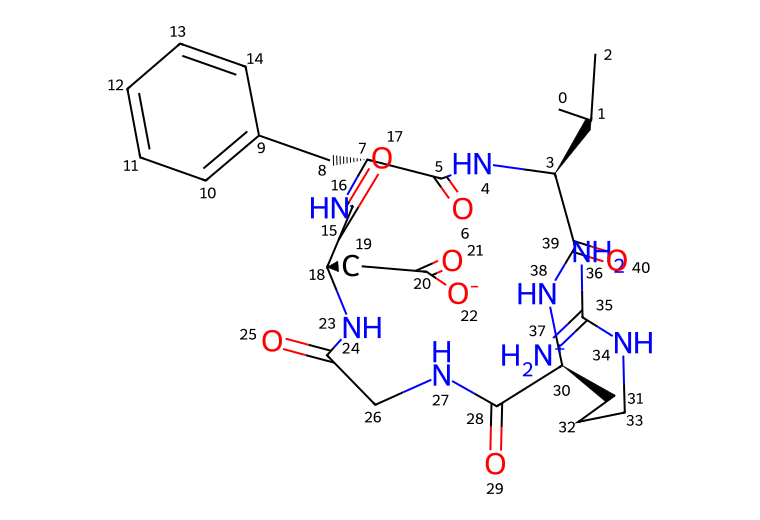

In [2]:
mol = Chem.SDMolSupplier(str(ROOT / "system/built.sdf"), removeHs=False)[0]
parts = [md.load(str(ROOT / f"REST2-run{r}/md_script/solute_state0_prod1.nc"),
                 top=str(ROOT / "system/built.solute.pdb"))[::75] for r in (1, 2, 3)]
traj = parts[0].join(parts[1]).join(parts[2])
mapping, why = verify_atom_mapping(mol, [(b[0].index, b[1].index) for b in traj.topology.bonds],
                                   [a.element.symbol for a in traj.topology.atoms])
print(Chem.MolToSmiles(Chem.RemoveHs(mol)), "|", mol.GetNumAtoms(), "atoms |", traj.n_frames, "frames")
print("atom mapping:", "identity" if mapping == list(range(mol.GetNumAtoms())) else mapping, "|", why)
drawer = rdMolDraw2D.MolDraw2DSVG(760, 520)
drawer.drawOptions().addAtomIndices = True
heavy = Chem.RemoveHs(mol)
rdMolDraw2D.PrepareMolForDrawing(heavy)
drawer.DrawMolecule(heavy); drawer.FinishDrawing()
display(SVG(drawer.GetDrawingText()))

## 2. The torsions

Backbone phi, psi and omega of the five residues (omega_i is CA(i)-C'(i)-N(i+1)-CA(i+1), the peptide
bond to the next residue in the ring), and two side-chain columns that carry the symmetry: valine
chi1 and the phenyl ring torsion chi2. The Arg and Asp side chains, the guanidinium and the
carboxylate are left out of the clustering and used in the last section. The indices are those of the
SDF drawn above.

In [3]:
BACKBONE_AND_SYMMETRIC = {
    "Val:phi": (5, 4, 3, 39), "Val:psi": (4, 3, 39, 38), "Val:omega": (3, 39, 38, 30),
    "Phe:phi": (16, 15, 7, 5), "Phe:psi": (15, 7, 5, 4), "Phe:omega": (7, 5, 4, 3),
    "Asp:phi": (24, 23, 18, 16), "Asp:psi": (23, 18, 16, 15), "Asp:omega": (18, 16, 15, 7),
    "Gly:phi": (28, 27, 26, 24), "Gly:psi": (27, 26, 24, 23), "Gly:omega": (26, 24, 23, 18),
    "Arg:phi": (39, 38, 30, 28), "Arg:psi": (38, 30, 28, 27), "Arg:omega": (30, 28, 27, 26),
    "Val:chi1": (4, 3, 1, 0), "Phe:chi2": (7, 8, 9, 10)}
SIDE_CHAINS = {"Phe:chi1": (15, 7, 8, 9), "Asp:chi1": (23, 18, 19, 20), "Asp:chi2": (18, 19, 20, 21),
               "Arg:chi1": (38, 30, 31, 32), "Arg:chi2": (30, 31, 32, 33),
               "Arg:chi3": (31, 32, 33, 34), "Arg:chi4": (32, 33, 34, 35)}
sym = lambda i: mol.GetAtomWithIdx(i).GetSymbol()
pd.DataFrame([{"torsion": n, "atoms": "-".join(map(str, q)), "elements": "".join(sym(i) for i in q)}
              for n, q in BACKBONE_AND_SYMMETRIC.items()]).set_index("torsion").T

torsion,Val:phi,Val:psi,Val:omega,Phe:phi,Phe:psi,Phe:omega,Asp:phi,Asp:psi,Asp:omega,Gly:phi,Gly:psi,Gly:omega,Arg:phi,Arg:psi,Arg:omega,Val:chi1,Phe:chi2
atoms,5-4-3-39,4-3-39-38,3-39-38-30,16-15-7-5,15-7-5-4,7-5-4-3,24-23-18-16,23-18-16-15,18-16-15-7,28-27-26-24,27-26-24-23,26-24-23-18,39-38-30-28,38-30-28-27,30-28-27-26,4-3-1-0,7-8-9-10
elements,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,NCCC,CCCC


## 3. The symmetry

The automorphisms of the canonicalised molecule collapse to **four operations on these 17 torsions**: the
identity, the phenyl flip, the swap of valine's methyls, and both. The images of `Val:chi1` and `Phe:chi2`
are added as columns, each orbit at weight 1/2, so the ring and the isopropyl count once. The carboxylate
and guanidinium exchanges move none of these 17 torsions; section 9 adds two that they do.

In [4]:
definitions = TorsionDefinitions(quads=tuple(BACKBONE_AND_SYMMETRIC.values()),
                                 names=tuple(BACKBONE_AND_SYMMETRIC), indexing="zero-based", units="radian")
enumeration = enumerate_symmetry(mol)
print(f"graph automorphisms: {enumeration.order} canonicalised, "
      f"{enumerate_symmetry(mol, canonicalize=False).order} for the drawn structure")
desc = SymmetricTorsionDescriptor(mol, definitions)
print(f"distinct operations on the descriptor: {len(desc.operations)} | columns: {desc.n_columns} | "
      f"group closure verified: {desc.group_closure_verified} | isometry verified: {desc.isometry_verified}")
print("orbits with more than one column:", [[desc.names[c] for c in o] for o in desc.orbits if len(o) > 1])
pd.DataFrame([{"operation": ("identity" if o.is_identity else f"op {o.index}"),
               "atoms exchanged": " ".join(f"{sym(i)}{i}" for i in o.moved_atoms()) or "-"}
              for o in desc.operations])

graph automorphisms: 147456 canonicalised, 36864 for the drawn structure


distinct operations on the descriptor: 4 | columns: 19 | group closure verified: True | isometry verified: True
orbits with more than one column: [['Val:chi1', 'Val:chi1@4-3-1-2'], ['Phe:chi2', 'Phe:chi2@7-8-9-14']]


,operation,atoms exchanged
0,identity,-
1,op 1,C10 C11 C13 C14 H53 H54 H56 H57
2,op 2,C0 C2 H41 H42 H43 H45 H46 H47
3,op 3,C0 C2 C10 C11 C13 C14 H41 H42 H43 H45 H46 H47 ...


operation 1 exchanges (atom pairs): [(10, 14), (11, 13), (53, 57), (54, 56)]


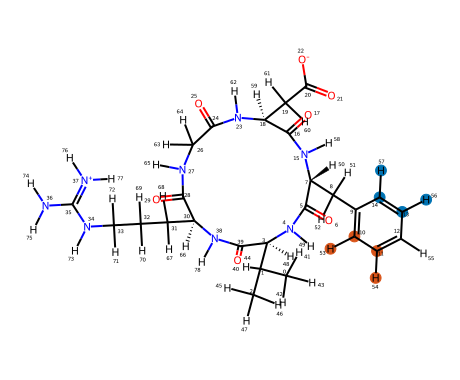

operation 2 exchanges (atom pairs): [(0, 2), (41, 45), (42, 46), (43, 47)]


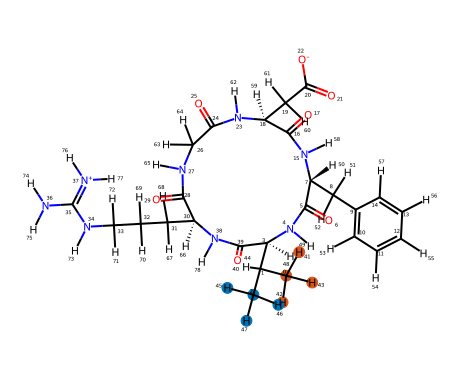

In [5]:
for k in (1, 2):
    info = draw_symmetry_operation(desc, k, output=scratch / f"op{k}.png")
    print(f"operation {k} exchanges (atom pairs):", info["exchanged_pairs"])
    display(Image(filename=str(scratch / f"op{k}.png")))

## 4. Clustering

The default `t_hdbscan` call: the symmetry-aware distance, a mass floor of 1 % of the fitted frames
(`min_cluster_size` 41 of 4002) and `min_samples` 40, and the 18-of-20 vote.

In [6]:
names = list(BACKBONE_AND_SYMMETRIC)
tors = md.compute_dihedrals(traj, list(BACKBONE_AND_SYMMETRIC.values()))
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=traj,
                atom_mapping=mapping).fit()
s = fit.summary()
print(f"{s['n_fit_frames']} frames, {s['n_clusters']} clusters, min_cluster_size "
      f"{s['settings']['min_cluster_size']}, min_samples {s['settings']['min_samples']}")
pd.DataFrame([{"cluster": group_name(c), "frames": int((fit.labels_ == c).sum()),
               "mass": round(float(fit.cluster_mass_[c]), 4)} for c in range(fit.n_clusters_)]
             + [{"cluster": "density noise", "frames": int((fit.labels_ == -2).sum()),
                 "mass": round(float(fit.noise_mass_), 4)},
                {"cluster": "ambiguous", "frames": int((fit.labels_ == -1).sum()),
                 "mass": round(float(fit.ambiguous_mass_), 4)}])

4002 frames, 2 clusters, min_cluster_size 41, min_samples 40


,cluster,frames,mass
0,A,3338,0.8341
1,B,580,0.1449
2,density noise,84,0.0210
3,ambiguous,0,0.0000


## 5. Every frame in one labelling

For the tables and figures below, each cluster's frames are written in the labelling nearest the cluster's
own density peak, and that peak in the labelling nearest the density peak of cluster A (`align_all`,
two levels). `margin < 0.1` is the fraction of frames for which that choice was close to arbitrary.

In [7]:
ref = fit.density_peak(0)
two = fit.align_all(per_cluster=True)
print(f"reference: frame {ref}, cluster {group_name(int(fit.labels_[ref]))}, core distance {fit.core_distance_[ref]:.3f}")
rows = []
for c in range(fit.n_clusters_):
    m = fit.labels_ == c
    used = np.bincount(two["operations"][m], minlength=len(desc.operations)) / m.sum()
    rows.append({"cluster": group_name(c), "density peak": int(two["cluster_references"][c]),
                 **{f"op {k}": round(float(used[k]), 3) for k in range(len(desc.operations))},
                 "mean distance, no relabelling": round(float(two["distance_identity"][m].mean()), 3),
                 "mean distance, nearest": round(float(two["distance"][m].mean()), 3),
                 "margin < 0.1": round(float((two["margin"][m] < 0.1).mean()), 3)})
pd.DataFrame(rows)

reference: frame 830, cluster A, core distance 0.629


,cluster,density peak,op 0,op 1,op 2,op 3,"mean distance, no relabelling","mean distance, nearest",margin < 0.1
0,A,830,0.296,0.285,0.222,0.198,2.330,1.789,0.018
1,B,4,0.229,0.245,0.233,0.293,2.549,1.949,0.028


## 6. The backbone, per cluster

Circular mean and circular standard deviation of phi, psi and omega in the one labelling. The
backbone columns are not moved by either operation, so these are the stored values.

In [8]:
def circ(values):
    R = np.hypot(np.sin(values).mean(), np.cos(values).mean())
    return np.rad2deg(np.arctan2(np.sin(values).mean(), np.cos(values).mean())), np.rad2deg(np.sqrt(-2.0 * np.log(max(R, 1e-12))))

backbone = [n for n in names if "chi" not in n]
rows = []
for n in backbone:
    row = {"torsion": n}
    for c in range(fit.n_clusters_):
        mean, sd = circ(two["selected"][fit.labels_ == c, names.index(n)])
        row[f"{group_name(c)} mean"], row[f"{group_name(c)} sd"] = round(mean, 1), round(sd, 1)
    rows.append(row)
pd.DataFrame(rows).set_index("torsion")

,A mean,A sd,B mean,B sd
torsion,,,,
Val:phi,-79.9,17.1,-82.8,17.3
Val:psi,-28.2,18.8,144.7,13.6
Val:omega,175.8,10.6,-179.6,9.7
Phe:phi,78.2,23.5,77.3,16.8
Phe:psi,-134.2,13.9,-122.7,25.4
Phe:omega,175.6,11.0,165.8,11.3
Asp:phi,-76.5,14.3,-78.6,30.0
Asp:psi,125.5,25.7,112.1,33.0
Asp:omega,-164.7,10.7,-160.1,9.5


## 7. Representative structures

The density peak of each cluster, superposed, hydrogens on carbon omitted.

51 atoms drawn, superposed: True


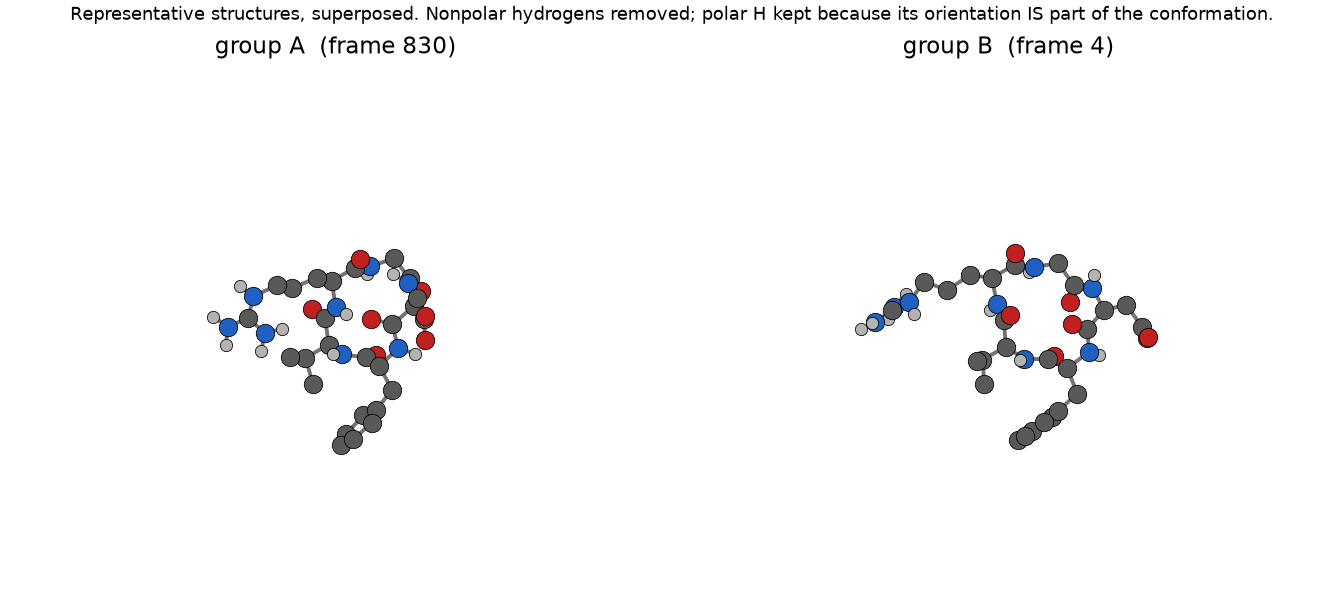

In [9]:
peaks = {group_name(c): two["cluster_references"][c] for c in range(fit.n_clusters_)}
keep = strip_nonpolar_hydrogens(traj)
info = draw_representative_structures(traj, peaks, output=scratch / "representatives.png", atom_indices=keep,
                                   label_atoms=False)
print(f"{info['n_atoms_drawn']} atoms drawn, superposed: {info['aligned']}")
display(Image(filename=str(scratch / "representatives.png")))

## 8. The choice of torsions matters

The same fit on the 17 columns above, on all 24 heavy-atom torsions (adding the Phe, Asp and Arg side
chains), and on the backbone and chi1 columns, each with `allow_single_cluster` on and off. The Arg
chi angles and the Asp carboxylate rotation are nearly uniform, which dilutes the density that
separates the backbone conformers.

In [10]:
everything = {**BACKBONE_AND_SYMMETRIC, **SIDE_CHAINS}
sets = {"17: backbone + symmetric columns (used above)": list(BACKBONE_AND_SYMMETRIC),
        "24: all heavy-atom torsions": list(everything),
        "20: backbone + every chi1 + the two symmetric columns": [n for n in everything
            if "chi" not in n or n.endswith("chi1") or n in ("Phe:chi2",)]}
rows = []
for label, sel in sets.items():
    defs = TorsionDefinitions(quads=tuple(everything[n] for n in sel), names=tuple(sel),
                              indexing="zero-based", units="radian")
    th = md.compute_dihedrals(traj, [everything[n] for n in sel])
    for flag in (True, False):
        f = t_hdbscan(th, molecule=mol, torsion_definitions=defs, coordinates=traj,
                      atom_mapping=mapping, allow_single_cluster=flag).fit()
        rows.append({"torsion set": label, "allow_single_cluster": flag, "clusters": f.n_clusters_,
                     "masses": [round(float(f.cluster_mass_[c]), 3) for c in range(f.n_clusters_)],
                     "noise": round(float(f.noise_mass_), 3)})
pd.DataFrame(rows)

,torsion set,allow_single_cluster,clusters,masses,noise
0,17: backbone + symmetric columns (used above),True,2,"[0.834, 0.145]",0.021
1,17: backbone + symmetric columns (used above),False,2,"[0.834, 0.145]",0.021
2,24: all heavy-atom torsions,True,1,[0.897],0.103
3,24: all heavy-atom torsions,False,2,"[0.812, 0.084]",0.103
4,20: backbone + every chi1 + the two symmetric ...,True,1,[0.977],0.023
5,20: backbone + every chi1 + the two symmetric ...,False,2,"[0.834, 0.143]",0.023


## 9. Two more columns: the carboxylate and the guanidinium

Asp `chi2` (CA-CB-CG-O) and the guanidinium torsion Arg `chi5` (CD-NE-CZ-NH) are each moved by an exchange
that only the canonical form of the molecule has (the two carboxylate oxygens, the two terminal nitrogens):
the descriptor then has 16 operations, and each of the two columns is folded instead of showing two peaks
half a turn apart ([Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/#3-canonicalization-atoms-the-drawing-keeps-apart)
draws both groups and these histograms).

In [11]:
RESONANT = {"Asp:chi2": (18, 19, 20, 21), "Arg:chi5": (33, 34, 35, 36)}
columns19 = {**BACKBONE_AND_SYMMETRIC, **RESONANT}
defs19 = TorsionDefinitions(quads=tuple(columns19.values()), names=tuple(columns19),
                            indexing="zero-based", units="radian")
tors19 = md.compute_dihedrals(traj, list(columns19.values()))
print("operations on the 19 torsions:", len(SymmetricTorsionDescriptor(mol, defs19).operations))

operations on the 19 torsions: 16


In [12]:
rows = []
for flag in (True, False):
    f = t_hdbscan(tors19, molecule=mol, torsion_definitions=defs19, coordinates=traj,
                  atom_mapping=mapping, allow_single_cluster=flag).fit()
    rows.append({"torsion set": "19: the 17 plus Asp chi2 and Arg chi5", "allow_single_cluster": flag,
                 "clusters": f.n_clusters_,
                 "masses": [round(float(f.cluster_mass_[c]), 3) for c in range(f.n_clusters_)],
                 "noise": round(float(f.noise_mass_), 3)})
pd.DataFrame(rows)

,torsion set,allow_single_cluster,clusters,masses,noise
0,19: the 17 plus Asp chi2 and Arg chi5,True,1,[0.975],0.025
1,19: the 17 plus Asp chi2 and Arg chi5,False,2,"[0.834, 0.142]",0.025


With the two columns added, `allow_single_cluster=True` merges the two clusters of section 4 into one,
and the default, `False`, keeps two: the density that separated them is the density of a 17-column
space, and two more columns change the estimate. This is the torsion-set dependence of section 8
again, and it is a property of the estimator, not of the canonicalization. It is why the default is
`False`.

## 10. Clustering on all the heavy-atom torsions

The same pipeline on all **24 heavy-atom torsions** of section 8: the 15 backbone phi, psi and omega, and the nine
side-chain torsions (Val `chi1`, Phe `chi1` and `chi2`, Asp `chi1` and `chi2`, Arg `chi1` to `chi4`). The two
symmetric pairs and the carboxylate pair are folded by the operations of section 3 and section 9; the default
`allow_single_cluster=False` is in force. The hydrogen torsions and the guanidinium `chi5` are not in this set.

In [13]:
def fit_set(names_used):
    defs = TorsionDefinitions(quads=tuple(everything[n] for n in names_used), names=tuple(names_used),
                              indexing="zero-based", units="radian")
    th = md.compute_dihedrals(traj, [everything[n] for n in names_used])
    return t_hdbscan(th, molecule=mol, torsion_definitions=defs, coordinates=traj,
                     atom_mapping=mapping).fit()

names24 = list(everything)
fit24 = fit_set(names24)
d24 = fit24.descriptor_
s24 = fit24.summary()
al24 = fit24.align_all(per_cluster=True)
print(f"{len(names24)} torsions, {d24.n_columns} columns once the images are added, {len(d24.operations)} operations")
print(f"{s24['n_fit_frames']} frames, {fit24.n_clusters_} clusters, min_cluster_size {s24['settings']['min_cluster_size']}, "
      f"min_samples {s24['settings']['min_samples']}, allow_single_cluster {s24['allow_single_cluster']}")
pd.DataFrame([{"cluster": group_name(c), "frames": int((fit24.labels_ == c).sum()),
               "mass": round(float(fit24.cluster_mass_[c]), 4),
               "density peak (frame)": int(al24["cluster_references"][c])} for c in range(fit24.n_clusters_)]
             + [{"cluster": "density noise", "frames": int((fit24.labels_ == -2).sum()),
                 "mass": round(float(fit24.noise_mass_), 4), "density peak (frame)": ""},
                {"cluster": "ambiguous", "frames": int((fit24.labels_ == -1).sum()),
                 "mass": round(float(fit24.ambiguous_mass_), 4), "density peak (frame)": ""}])

24 torsions, 27 columns once the images are added, 8 operations
4002 frames, 2 clusters, min_cluster_size 41, min_samples 40, allow_single_cluster False


,cluster,frames,mass,density peak (frame)
0,A,3250,0.8121,772
1,B,338,0.0845,4
2,density noise,414,0.1034,
3,ambiguous,0,0.0000,


The 24 torsions, every frame written in the labelling nearest the reference (two levels, as in section 5).
Colours are the clusters; frames in no cluster are not drawn.

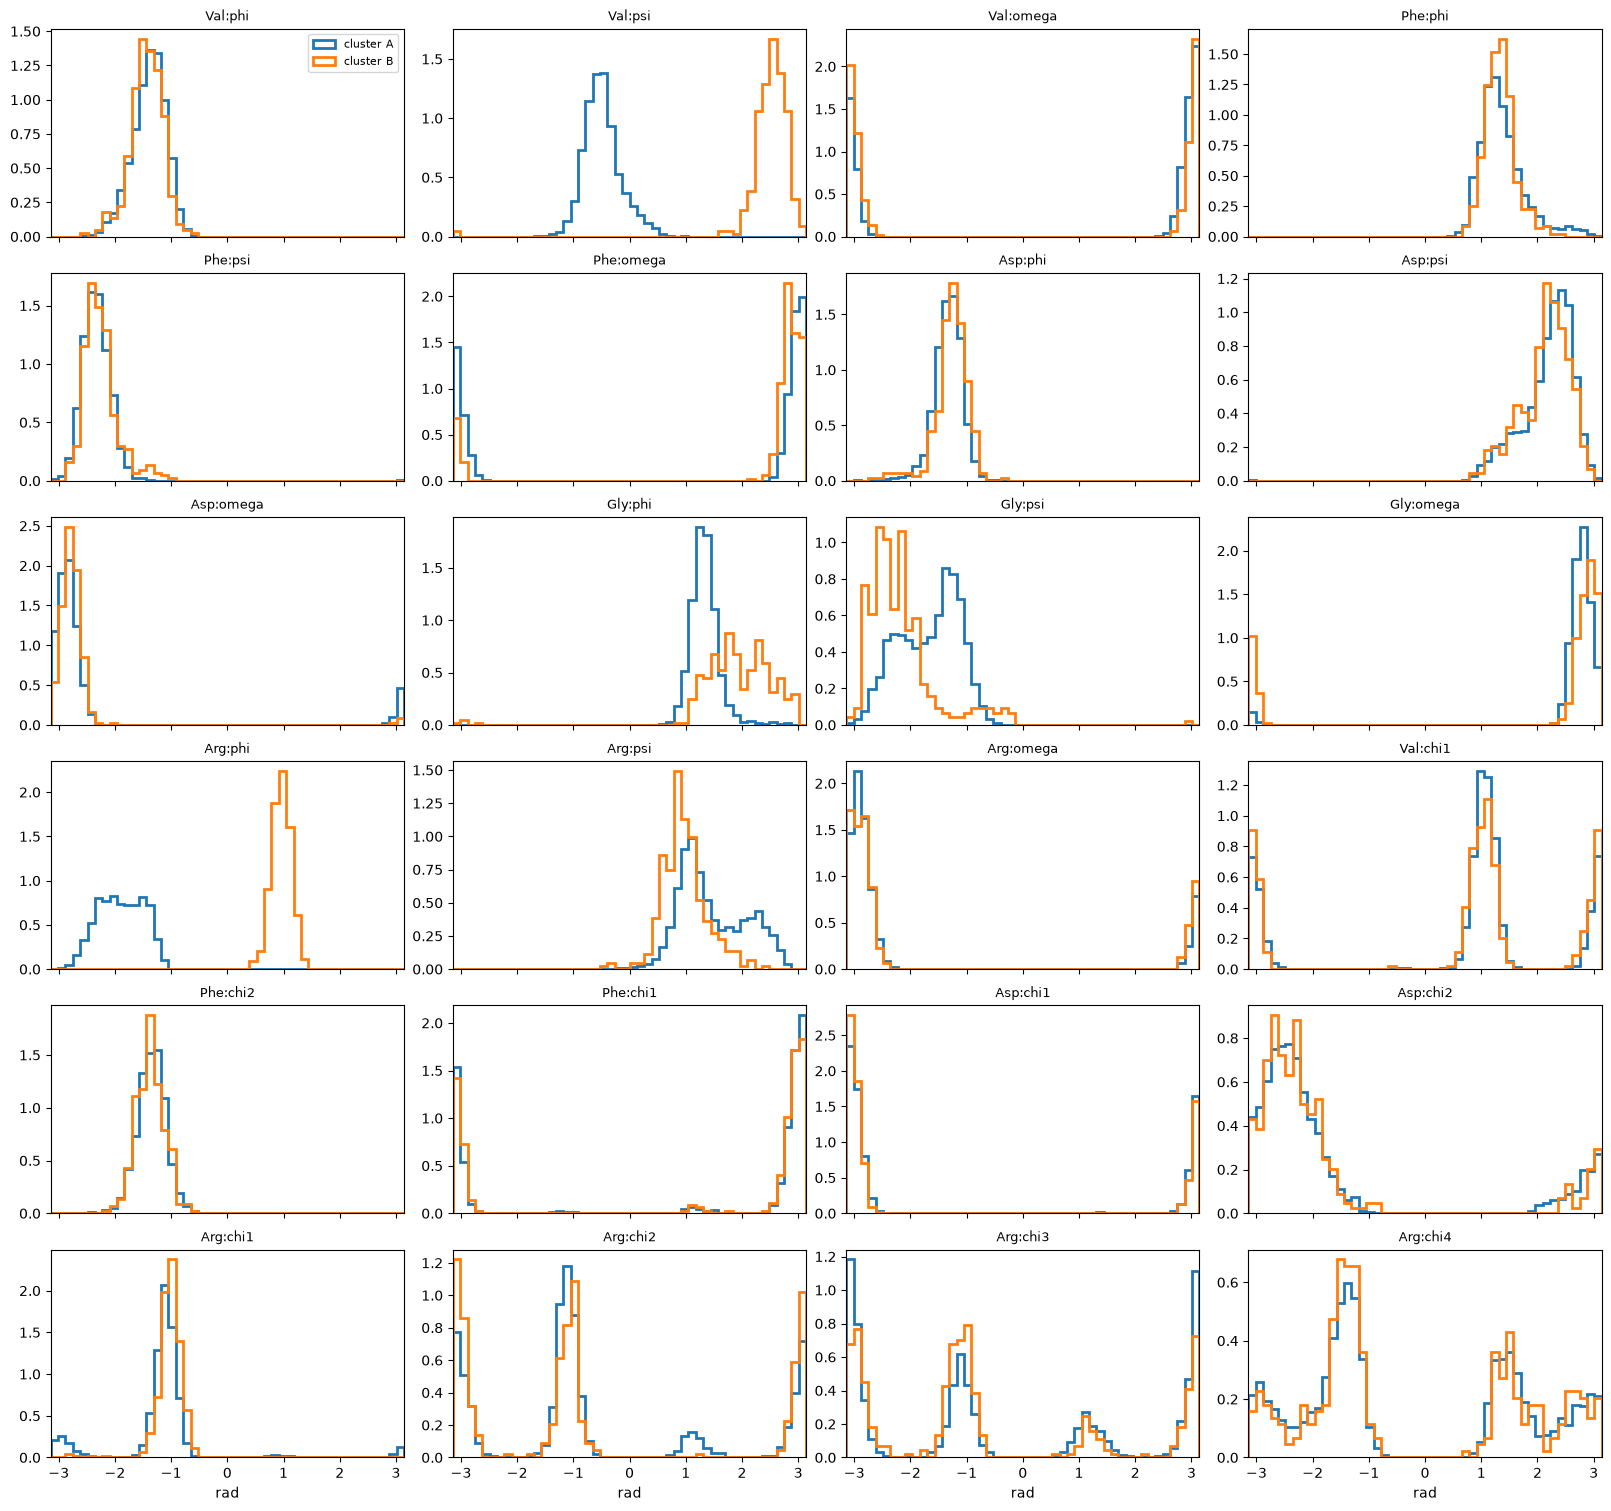

In [14]:
fig, axes = plt.subplots(6, 4, figsize=(16, 15), layout="constrained", sharex=True)
for j, name in enumerate(names24):
    ax = axes.flat[j]
    for c in range(fit24.n_clusters_):
        ax.hist(al24["selected"][fit24.labels_ == c, j], bins=edges, density=True, histtype="step", lw=2.0,
                color=palette(c), label=f"cluster {group_name(c)}")
    ax.set_xlim(-np.pi, np.pi); ax.set_title(names24[j], fontsize=9)
axes.flat[0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("rad")
plt.show()

Circular mean and circular standard deviation of each torsion in each cluster, in the same labelling.

In [15]:
rows = []
for j, n in enumerate(names24):
    row = {"torsion": n}
    for c in range(fit24.n_clusters_):
        mean, sd = circ(al24["selected"][fit24.labels_ == c, j])
        row[f"{group_name(c)} mean"], row[f"{group_name(c)} sd"] = round(mean, 1), round(sd, 1)
    rows.append(row)
pd.DataFrame(rows).set_index("torsion")

,A mean,A sd,B mean,B sd
torsion,,,,
Val:phi,-80.0,17.1,-82.6,16.2
Val:psi,-28.1,18.8,145.3,13.9
Val:omega,175.9,10.4,-179.6,9.9
Phe:phi,77.8,23.1,76.3,15.5
Phe:psi,-134.0,13.7,-129.7,17.6
Phe:omega,175.4,10.9,166.7,10.9
Asp:phi,-76.5,14.2,-72.9,17.1
Asp:psi,125.8,25.3,122.1,24.6
Asp:omega,-164.7,10.7,-160.1,9.4


density peak of each cluster, 51 atoms drawn, superposed: True


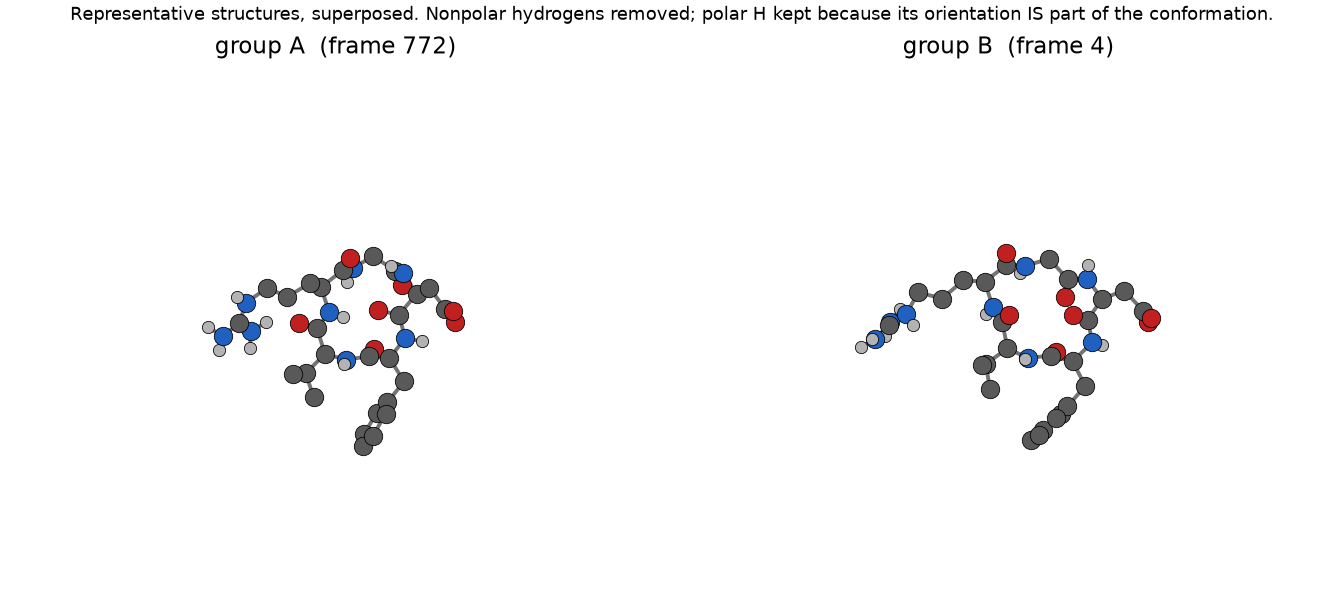

In [16]:
peaks24 = {group_name(c): al24["cluster_references"][c] for c in range(fit24.n_clusters_)}
info = draw_representative_structures(traj, peaks24, output=scratch / "representatives24.png",
                                      atom_indices=strip_nonpolar_hydrogens(traj), label_atoms=False)
print(f"density peak of each cluster, {info['n_atoms_drawn']} atoms drawn, superposed: {info['aligned']}")
display(Image(filename=str(scratch / "representatives24.png")))

## 11. Between the clusters: symmetry-corrected RMSD

For two clusterings of the same 4002 frames, the mean and standard deviation of the **heavy-atom RMSD**
between every frame of one cluster and every frame of another, after superposition and **minimised over
the symmetry operations** (16 on the heavy atoms: the phenyl flip, the valine methyls, the carboxylate
and the guanidinium, in every combination). The diagonal is the spread inside a cluster, over distinct
pairs. Clusters of more than 1500 frames are represented by 1500 drawn at random (seed 0). Heavy atoms
only, by choice. The explanation is in
[Torsion preprocessing](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-preprocessing/#9-symmetry-corrected-rmsd).

* **(a) backbone only:** the 15 phi, psi and omega torsions.
* **(b) heavy-atom torsions:** all 24 heavy-atom torsions, the clustering of section 10.

In [17]:
from md_tools.analysis import heavy_atoms, operations_on_atoms, intercluster_rmsd

heavy = heavy_atoms(mol)
operations = operations_on_atoms(enumeration, heavy)
Xheavy = traj.xyz[:, heavy, :] * 10.0                                  # nm -> A

clusterings = {"(a) backbone only, 15 torsions": fit_set([n for n in BACKBONE_AND_SYMMETRIC if "chi" not in n]),
               "(b) heavy-atom torsions, 24": fit24}
results = {}
for label, f in clusterings.items():
    results[label] = {"corrected": intercluster_rmsd(Xheavy, f.labels_, operations, max_per_cluster=1500, workers=4),
                      "by_index": intercluster_rmsd(Xheavy, f.labels_, operations[:1], max_per_cluster=1500, workers=4)}
    print(f"{label}: {f.n_clusters_} clusters, masses {[round(float(f.cluster_mass_[c]), 3) for c in range(f.n_clusters_)]}, "
          f"noise {f.noise_mass_:.3f}")
def as_table(r):
    n = len(r["clusters"]); nm = [group_name(c) for c in r["clusters"]]
    return pd.DataFrame([[f"{r['mean'][i, j]:.2f} +- {r['std'][i, j]:.2f}" for j in range(n)] for i in range(n)],
                        index=nm, columns=nm)
for label, r in results.items():
    print(f"\n{label}: frames used {r['corrected']['n_frames']} of {r['corrected']['n_frames_in_cluster']}")
    print("symmetry-corrected heavy-atom RMSD (A), mean +- std:"); display(as_table(r["corrected"]))
    print("by atom index (no symmetry), mean +- std:"); display(as_table(r["by_index"]))

(a) backbone only, 15 torsions: 2 clusters, masses [0.834, 0.144], noise 0.022


(b) heavy-atom torsions, 24: 2 clusters, masses [0.812, 0.084], noise 0.103

(a) backbone only, 15 torsions: frames used {0: 1500, 1: 576} of {0: 3339, 1: 576}
symmetry-corrected heavy-atom RMSD (A), mean +- std:


,A,B
A,1.56 +- 0.47,1.88 +- 0.49
B,1.88 +- 0.49,1.70 +- 0.56


by atom index (no symmetry), mean +- std:


,A,B
A,1.71 +- 0.43,2.00 +- 0.46
B,2.00 +- 0.46,1.83 +- 0.51



(b) heavy-atom torsions, 24: frames used {0: 1500, 1: 338} of {0: 3250, 1: 338}
symmetry-corrected heavy-atom RMSD (A), mean +- std:


,A,B
A,1.56 +- 0.47,1.75 +- 0.44
B,1.75 +- 0.44,1.40 +- 0.45


by atom index (no symmetry), mean +- std:


,A,B
A,1.71 +- 0.44,1.88 +- 0.41
B,1.88 +- 0.41,1.56 +- 0.42


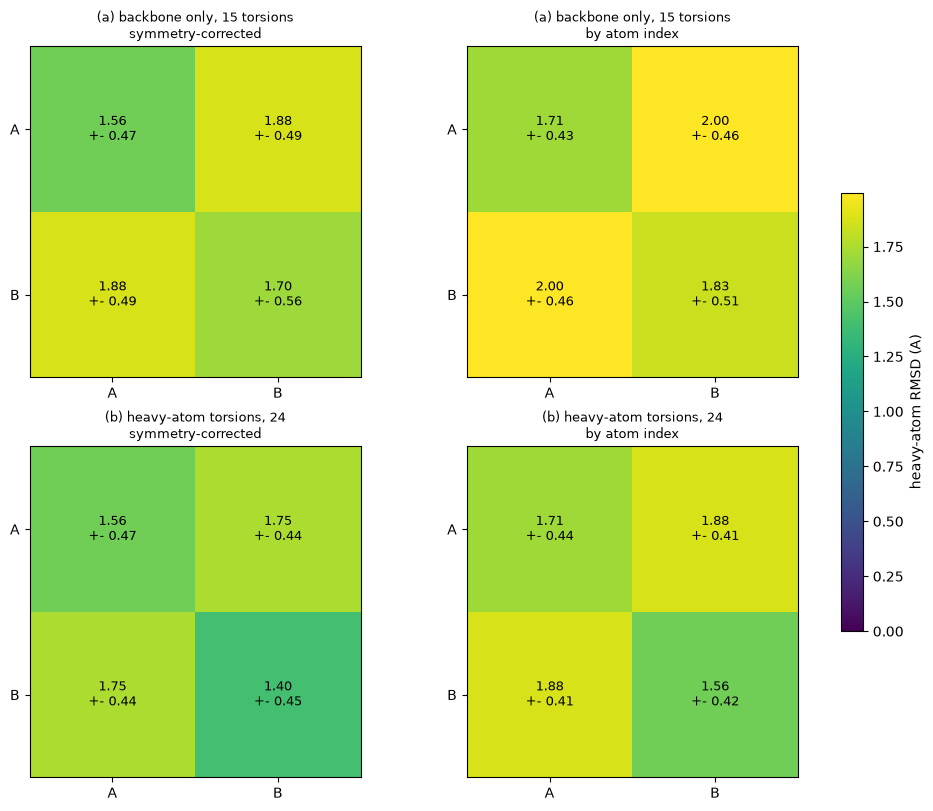

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), layout="constrained")
top = max(r[k]["mean"].max() for r in results.values() for k in ("corrected", "by_index"))
for row, (label, r) in enumerate(results.items()):
    for col, (title, key) in enumerate((("symmetry-corrected", "corrected"), ("by atom index", "by_index"))):
        ax, m, sd = axes[row, col], r[key]["mean"], r[key]["std"]
        nm = [group_name(c) for c in r[key]["clusters"]]
        im = ax.imshow(m, cmap="viridis", vmin=0, vmax=top)
        ax.set_xticks(range(len(nm)), nm); ax.set_yticks(range(len(nm)), nm)
        for i in range(len(nm)):
            for j in range(len(nm)):
                ax.text(j, i, f"{m[i, j]:.2f}\n+- {sd[i, j]:.2f}", ha="center", va="center",
                        color="w" if m[i, j] < 0.6 * top else "k", fontsize=9)
        ax.set_title(f"{label}\n{title}", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.6, label="heavy-atom RMSD (A)")
plt.show()

**Reading the matrices.** Each entry is the mean ± standard deviation of the heavy-atom RMSD over pairs of frames, and the diagonal is the spread inside a cluster. In both clusterings the clusters are only modestly apart: between A and B is 1.88 ± 0.49 A against 1.56 ± 0.47 A inside A for the backbone-only clustering, and 1.75 ± 0.44 A against 1.56 A for the heavy-atom torsions, so the distributions overlap and a single RMSD cannot assign a frame to a cluster; the torsions do. Cluster B of the heavy-atom clustering (338 frames) is the most compact, 1.40 ± 0.45 A. The symmetry correction lowers every entry by 0.1 to 0.2 A: the by-index matrices are what MDTraj or pytraj would report, and they count each relabelling as motion. Clusters of more than 1500 frames are represented by 1500 drawn at random, so the entries carry that sampling as well.

## 12. Torsion partitioning on the backbone

`cut_clustering` cuts the free-energy profiles of the 15 backbone torsions, recursively, at barriers of at
least 1 kT, leaving no piece under 0.1 % of the frames and no two cuts closer than 60 degrees. It needs no
distance matrix, so it reads **every frame** of the three runs, 300 000, not the 4002 above. No symmetry
operation moves a backbone torsion, so the coordinates are the torsions themselves.

In [19]:
BACKBONE = {n: q for n, q in BACKBONE_AND_SYMMETRIC.items() if "chi" not in n}
full = [md.load(str(ROOT / f"REST2-run{r}/md_script/solute_state0_prod1.nc"),
                top=str(ROOT / "system/built.solute.pdb")) for r in (1, 2, 3)]
per_run = [p.n_frames for p in full]
full = full[0].join(full[1]).join(full[2])
defs15 = TorsionDefinitions(quads=tuple(BACKBONE.values()), names=tuple(BACKBONE), indexing="zero-based", units="radian")
tors15 = md.compute_dihedrals(full, list(BACKBONE.values()))
cells15 = cut_clustering(t_hdbscan(tors15, molecule=mol, torsion_definitions=defs15, coordinates=full,
                                   atom_mapping=mapping))
print(f"frames per run {per_run}; {cells15['n_clusters']} clusters")
print("\n".join(cells15["log"]))

frames per run [100000, 100000, 100000]; 9 clusters
300000 frames: periodic cut on Phe:phi (empty bins) -> 1286 + 298714
  1286 frames: periodic cut on Val:psi (empty bins) -> 487 + 799
  298714 frames: periodic cut on Arg:phi (empty bins) -> 43799 + 254915
    43799 frames: periodic cut on Asp:phi (barrier 5.51 kT at E*=5.11) -> 41287 + 2512
      41287 frames: periodic cut on Gly:phi (barrier 2.02 kT at E*=1.61) -> 38923 + 2364
    254915 frames: periodic cut on Asp:phi (empty bins) -> 2130 + 252785
      252785 frames: periodic cut on Arg:psi (barrier 2.54 kT at E*=2.33) -> 251759 + 1026
        251759 frames: periodic cut on Gly:phi (barrier 1.27 kT at E*=1.00) -> 251182 + 577


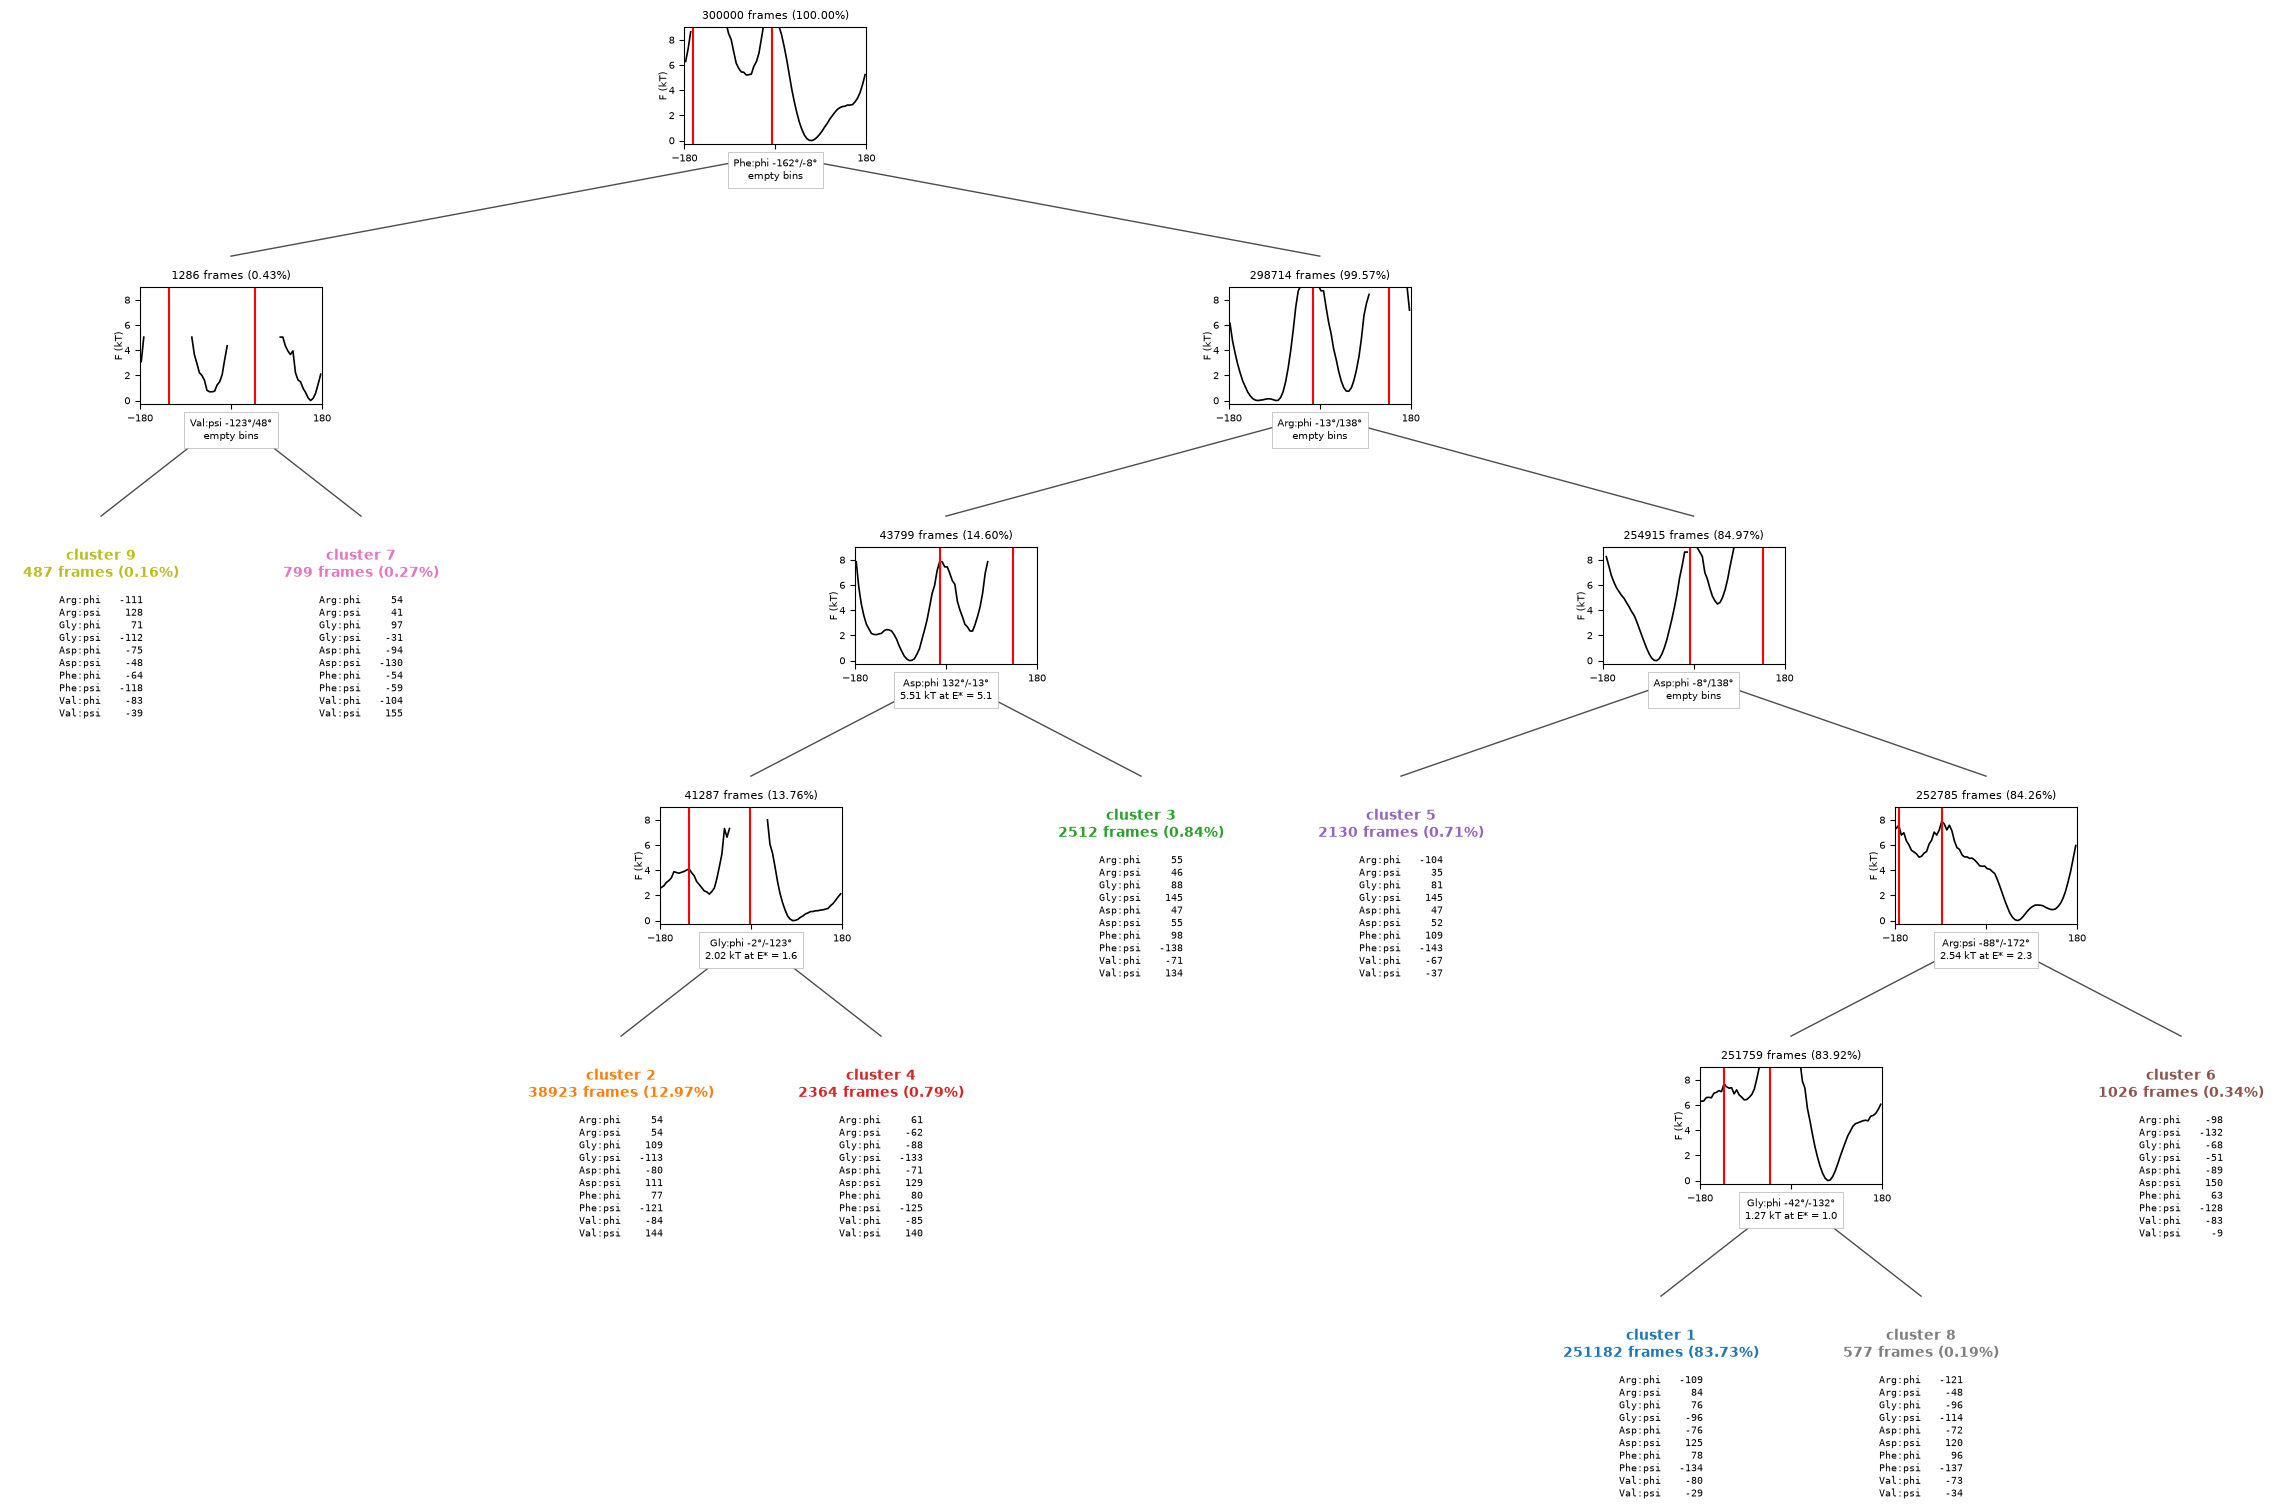

In [20]:
plot_split_tree(cells15, leaf_torsions=[f"{r}:{t}" for r in ("Arg", "Gly", "Asp", "Phe", "Val") for t in ("phi", "psi")]);

Each cut cell shows the free energy, over its own frames, of the torsion cut there (red: the cut; grey dashed:
the boundaries the cell inherited on that torsion); each leaf the circular mean of every phi and psi.
Which run each cluster's frames come from:

In [21]:
run = np.repeat([1, 2, 3], per_run)
rows = []
for c in range(cells15["n_clusters"]):
    m = cells15["labels"] == c
    share = np.bincount(run[m], minlength=4)[1:] / m.sum()
    rows.append({"cluster": c + 1, "frames": int(m.sum()), "mass (%)": round(100 * cells15["cluster_mass"][c], 2),
                 **{f"run {r} (%)": round(100 * share[r - 1]) for r in (1, 2, 3)}})
pd.DataFrame(rows)

,cluster,frames,mass (%),run 1 (%),run 2 (%),run 3 (%)
0,1,251182,83.73,34,34,32
1,2,38923,12.97,29,31,40
2,3,2512,0.84,13,7,80
3,4,2364,0.79,28,34,39
4,5,2130,0.71,26,59,15
5,6,1026,0.34,39,33,29
6,7,799,0.27,11,71,18
7,8,577,0.19,43,29,28
8,9,487,0.16,52,31,17


The two large clusters are sampled evenly by the three runs. Two of the small ones are not: cluster 3 comes
80 % from run 3 and cluster 7 71 % from run 2. A cluster that comes mostly from one run is a region that run
visited and the others hardly did, so its mass is not converged, whatever the barriers around it.

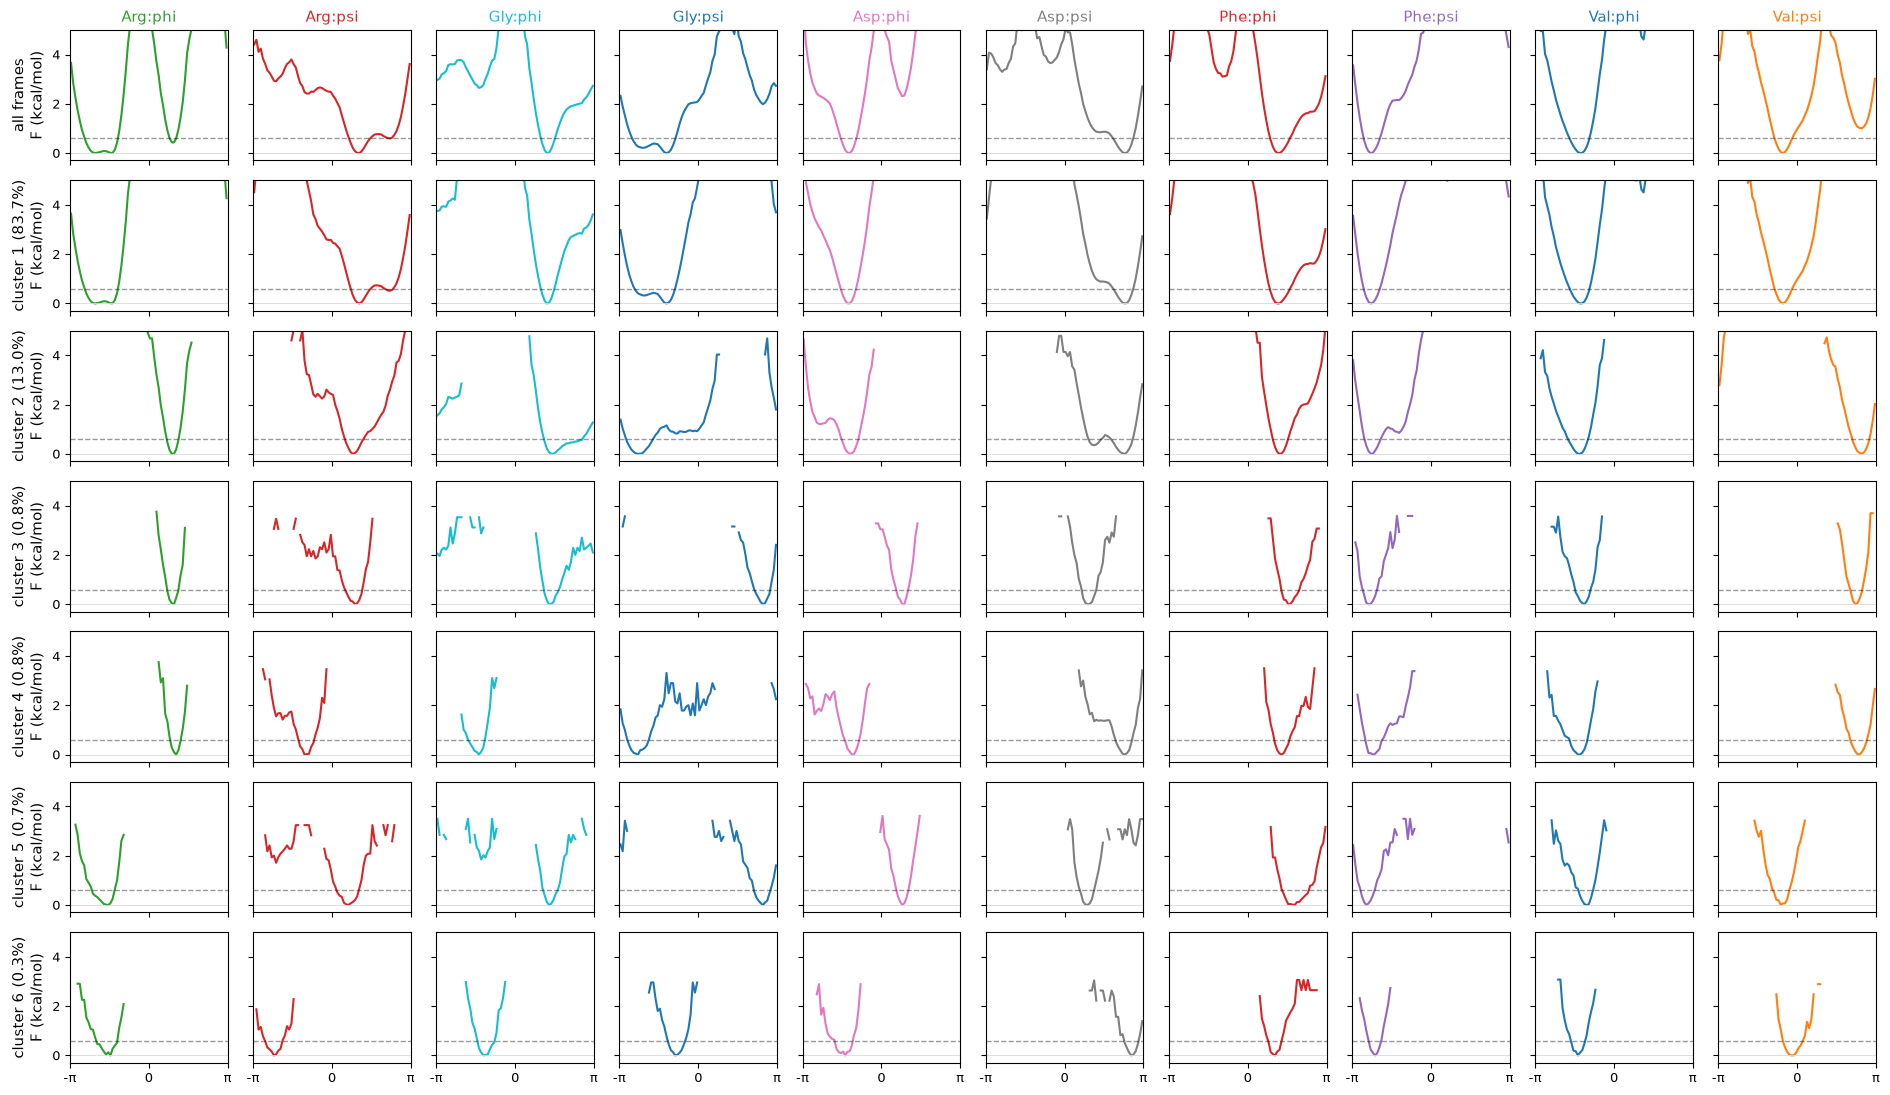

In [22]:
plot_hist(cells15, n_cluster=6, kind="free_energy", show_molecule=False,
          torsion_show=[f"{r}:{t}" for r in ("Arg", "Gly", "Asp", "Phe", "Val") for t in ("phi", "psi")]);

### Against HDBSCAN

The 4002 frames of section 4 are every 75th frame of each run, so each has a torsion-partitioning label:

In [23]:
offsets = np.concatenate([[0], np.cumsum(per_run)[:-1]])
picked = np.concatenate([o + np.arange(0, n, 75) for o, n in zip(offsets, per_run)])
assert len(picked) == len(fit.labels_)
name = lambda c: {-2: "noise", -1: "ambiguous"}[c] if c < 0 else f"HDBSCAN {group_name(c)}"
pd.crosstab(pd.Series([f"cell {c + 1}" for c in cells15["labels"][picked]], name="torsion partitioning"),
            pd.Series([name(c) for c in fit.labels_], name="HDBSCAN, 17 torsions"))

"HDBSCAN, 17 torsions",HDBSCAN A,HDBSCAN B,noise
torsion partitioning,,,
cell 1,3337,0,0
cell 2,0,533,0
cell 3,0,13,17
cell 4,0,34,2
cell 5,1,0,24
cell 6,0,0,16
cell 7,0,0,12
cell 8,0,0,8
cell 9,0,0,5


Cell 1 is HDBSCAN's A, and cell 2 most of B: 47 of B's frames fall in cells 3 and 4, which the cell
partitioning splits off its edge. Every one of HDBSCAN's 84 noise frames is in one of the seven small cells
(3 to 9), each under HDBSCAN's 1 % floor. Whether a small cluster is a state is a question for the per-run table above, not for
either method.